# Roteiro 12 - CNN

Este é o roteiro da décima terceira aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

O objetivo é desenvolver classificadores com CNN - Redes convolucionais usando os dados dos roteiros 9 e 10.

O documento está organizado da seguinte forma:

    CNN simples
    CNN melhorando
    Transferência de aprendizado

*__________________*

Autor: raoni.teixeira@ufmt.br

# CNN

Considere novamente o conjunto de dígitos manuscritos utilizados nas aulas 9 e 10.

# Baixando os dados

In [ ]:
!gdown 1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz

Downloading...
From (original): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz
From (redirected): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz&confirm=t&uuid=4ba3ffa7-2662-4bef-8300-33b21d63b0a9
To: /content/mnistdata.mat
100% 7.51M/7.51M [00:00<00:00, 29.5MB/s]


# Carregando bibliotecas

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import numpy as np
from scipy.io import loadmat


In [ ]:
def load_data():
    data = loadmat("mnistdata.mat")
    X = data["X"]
    # Para CNN, X deve ser uma matriz. Novo shape: (5000, 1, 20, 20)
    X = X.reshape(-1, 1, 20, 20)
    y = data["y"].flatten()
    return X, y

print("Carregando dados...")
X, y = load_data()
y[y == 10] = 0

Carregando dados...


## Primeiro modelo

In [ ]:
# Configuração inicial
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 0.001


# Dividir dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X.astype(np.float32), y, test_size=0.2, random_state=42
)

# Converter para tensores PyTorch
train_data = torch.tensor(X_train).to(device)
train_labels = torch.tensor(y_train).to(device)
test_data = torch.tensor(X_test).to(device)
test_labels = torch.tensor(y_test).to(device)

# Criar DataLoaders
train_dataset = TensorDataset(train_data, train_labels)
test_dataset = TensorDataset(test_data, test_labels)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=True if device.type == 'cuda' else False
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True if device.type == 'cuda' else False
)

# Definir a arquitetura da CNN corrigida
class DigitCNN(nn.Module):
    def __init__(self):
        super(DigitCNN, self).__init__()

        self.feature_extractor = nn.Sequential(
            # Conv1: 1 canal de entrada -> 32 canais de saída
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 20x20 -> 10x10

            # Conv2: 32 -> 64 canais
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 10x10 -> 5x5
        )

        self.classifier = nn.Sequential(
            nn.Linear(64 * 5 * 5, 128),
            nn.ReLU(),
            #nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.feature_extractor(x)
        x = x.view(x.size(0), -1)  # Achatar para vetor
        x = self.classifier(x)
        return x

# Inicializar modelo, loss e otimizador
model = DigitCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Loop de treinamento
for epoch in range(EPOCHS):
    # Treino
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward e otimização
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    # Cálculo da perda média
    train_loss = train_loss / len(train_loader.dataset)

    # Validação
    model.eval()
    correct = 0
    total = 0
    test_loss = 0.0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    # Estatísticas
    test_loss = test_loss / len(test_loader.dataset)
    accuracy = 100 * correct / total

    print(f'Epoch [{epoch+1}/{EPOCHS}] => '
          f'Train Loss: {train_loss:.4f}, '
          f'Test Loss: {test_loss:.4f}, '
          f'Accuracy: {accuracy:.2f}%')

# Avaliação final
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'\nFinal Test Accuracy: {100 * correct / total:.2f}%')
print('Treinamento concluído!')

Epoch [1/30] => Train Loss: 1.1617, Test Loss: 0.4642, Accuracy: 86.00%
Epoch [2/30] => Train Loss: 0.3542, Test Loss: 0.3095, Accuracy: 92.10%
Epoch [3/30] => Train Loss: 0.2351, Test Loss: 0.2141, Accuracy: 94.50%
Epoch [4/30] => Train Loss: 0.1517, Test Loss: 0.2214, Accuracy: 93.20%
Epoch [5/30] => Train Loss: 0.1250, Test Loss: 0.1721, Accuracy: 95.50%
Epoch [6/30] => Train Loss: 0.0973, Test Loss: 0.1611, Accuracy: 95.80%
Epoch [7/30] => Train Loss: 0.0819, Test Loss: 0.1399, Accuracy: 96.40%
Epoch [8/30] => Train Loss: 0.0622, Test Loss: 0.1461, Accuracy: 96.20%
Epoch [9/30] => Train Loss: 0.0507, Test Loss: 0.1512, Accuracy: 95.30%
Epoch [10/30] => Train Loss: 0.0542, Test Loss: 0.1376, Accuracy: 96.40%
Epoch [11/30] => Train Loss: 0.0437, Test Loss: 0.1160, Accuracy: 97.30%
Epoch [12/30] => Train Loss: 0.0296, Test Loss: 0.1221, Accuracy: 97.30%
Epoch [13/30] => Train Loss: 0.0250, Test Loss: 0.1197, Accuracy: 96.90%
Epoch [14/30] => Train Loss: 0.0223, Test Loss: 0.1311, Accu

# CNN 2

In [ ]:
import torch
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

# Transformações
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(64),  # AlexNet requer tamanho mínimo
    transforms.Grayscale(num_output_channels=3),  # Converter para 3 canais
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])  # Para 3 canais
])

# Função para aplicar transformações
def prepare_data(X, y, transform):
    data = []
    for img, label in zip(X, y):
        img_reshaped = (img.reshape(20, 20) * 255).astype(np.uint8)
        data.append((transform(img_reshaped), label))
    return data

# Preparar datasets
train_data = prepare_data(X_train, y_train, transform)
test_data = prepare_data(X_test, y_test, transform)

# DataLoaders
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

Epoch 1/40, Train Loss: 0.4462, Test Loss: 0.1705, Accuracy: 94.80%
Epoch 2/40, Train Loss: 0.1329, Test Loss: 0.0884, Accuracy: 98.00%
Epoch 3/40, Train Loss: 0.0924, Test Loss: 0.0801, Accuracy: 97.80%
Epoch 4/40, Train Loss: 0.0705, Test Loss: 0.0732, Accuracy: 97.60%
Epoch 5/40, Train Loss: 0.0591, Test Loss: 0.0817, Accuracy: 97.60%
Epoch 6/40, Train Loss: 0.0428, Test Loss: 0.0778, Accuracy: 97.60%
Epoch 7/40, Train Loss: 0.0443, Test Loss: 0.0644, Accuracy: 98.40%
Epoch 8/40, Train Loss: 0.0410, Test Loss: 0.0554, Accuracy: 98.00%
Epoch 9/40, Train Loss: 0.0339, Test Loss: 0.0601, Accuracy: 98.60%
Epoch 10/40, Train Loss: 0.0249, Test Loss: 0.0556, Accuracy: 98.00%
Epoch 11/40, Train Loss: 0.0205, Test Loss: 0.0719, Accuracy: 98.20%
Epoch 12/40, Train Loss: 0.0196, Test Loss: 0.0710, Accuracy: 98.00%
Epoch 13/40, Train Loss: 0.0123, Test Loss: 0.0745, Accuracy: 97.60%
Epoch 14/40, Train Loss: 0.0114, Test Loss: 0.0590, Accuracy: 97.80%
Epoch 15/40, Train Loss: 0.0071, Test Loss:

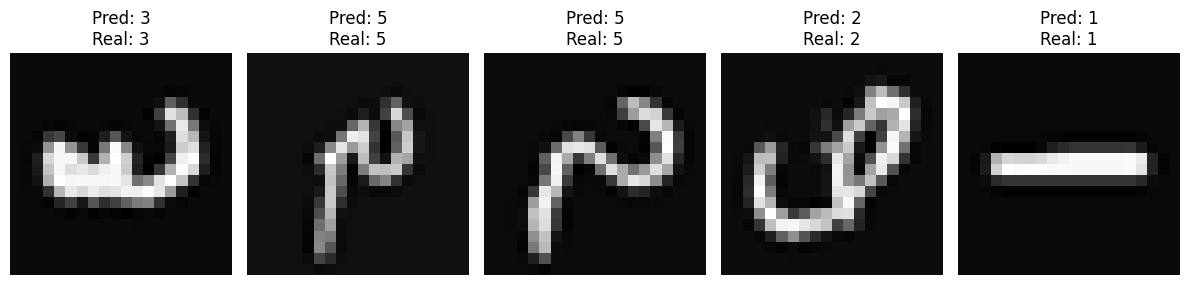

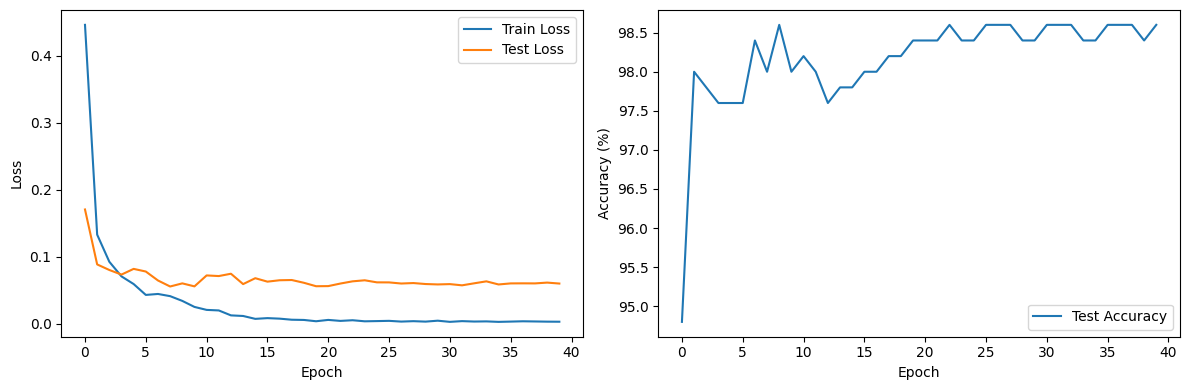

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Definindo um Dataset personalizado para seus dados
class DigitDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]

        # Converter para formato correto (1 canal, já que é em escala de cinza)
        image = image.reshape(20, 20)

        # Converter para tensor
        image = torch.FloatTensor(image).unsqueeze(0)  # Adiciona canal

        # Aplicar transformações, se houver
        if self.transform:
            image = self.transform(image)

        return image, label

class DigitClassifier(nn.Module):
    def __init__(self, num_classes=10):
        super(DigitClassifier, self).__init__()


        # Camadas convolucionais
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.25),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(64),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.25)
        )

        # Calculando o tamanho das features após o processamento
        # Input: 20x20 -> Após 2 MaxPooling: 5x5 com 64 canais
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(5 * 5 * 64, 512),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(512),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Função para carregar e preparar os dados
def prepare_data(X, y, test_size=0.1):
    # Dividir em conjuntos de treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)

    #
    transform = transforms.Compose([
        transforms.Resize((20, 20)),  # Garantir que o tamanho está correto
    ])

    # Criar datasets
    train_dataset = DigitDataset(X_train, y_train, transform=transform)
    test_dataset = DigitDataset(X_test, y_test, transform=transform)

    # Criar dataloaders
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

    return train_loader, test_loader

# Função para treinar o modelo
def train_model(model, train_loader, test_loader, epochs=10, lr=0.001):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)

    train_losses = []
    test_losses = []
    test_accuracies = []

    for epoch in range(epochs):
        # Treinamento
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_train_loss = running_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # Avaliação
        model.eval()
        test_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                test_loss += loss.item()

                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        avg_test_loss = test_loss / len(test_loader)
        test_losses.append(avg_test_loss)

        accuracy = 100 * correct / total
        test_accuracies.append(accuracy)

        scheduler.step(avg_test_loss)

        print(f'Epoch {epoch+1}/{epochs}, '
              f'Train Loss: {avg_train_loss:.4f}, '
              f'Test Loss: {avg_test_loss:.4f}, '
              f'Accuracy: {accuracy:.2f}%')

    return train_losses, test_losses, test_accuracies

# Função para visualizar algumas previsões
def visualize_predictions(model, test_loader, num_images=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()

    dataiter = iter(test_loader)
    images, labels = next(dataiter)

    with torch.no_grad():
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

    # Plotar as imagens e previsões
    fig, axes = plt.subplots(1, num_images, figsize=(12, 3))

    for i in range(num_images):
        axes[i].imshow(images[i].cpu().numpy()[0], cmap='gray')
        axes[i].set_title(f'Pred: {predicted[i].item()}\nReal: {labels[i].item()}')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Preparar os dados
train_loader, test_loader = prepare_data(X, y)

# Criar e treinar o modelo
model = DigitClassifier(num_classes=10)
train_losses, test_losses, test_accuracies = train_model(model, train_loader, test_loader, epochs=40)

# Visualizar algumas previsões
visualize_predictions(model, test_loader)

# Plotar o histórico de treinamento
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(test_accuracies, label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.tight_layout()
plt.show()

# Salvar o modelo treinado
torch.save(model.state_dict(), 'digit_classifier.pth')


Usando device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 22.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 617kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.63MB/s]


Modelo pré-treinado carregado com sucesso!
Aplicando T-SNE em 10000 amostras com 512 dimensões...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


T-SNE concluído em 115.66 segundos


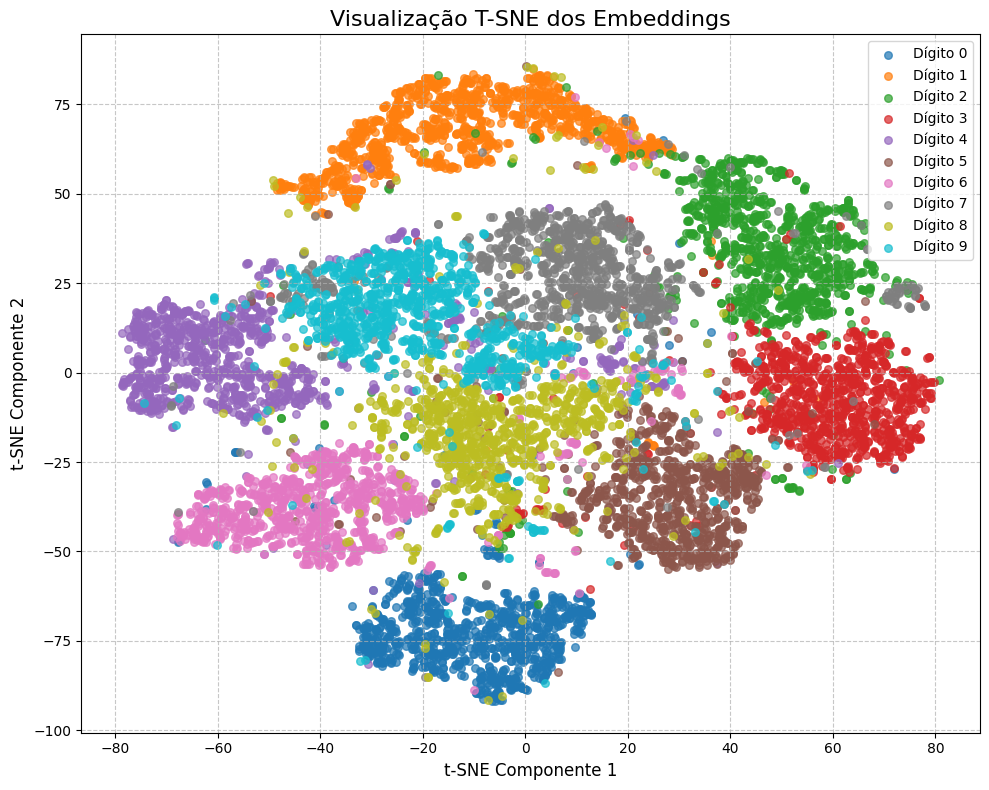

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import time

# Função para extrair embeddings das camadas intermediárias do modelo
def extract_embeddings(model, dataloader, device):
    model.eval()

    # Criar um modelo modificado que retorna embeddings intermediários
    class ModelWithEmbedding(nn.Module):
        def __init__(self, original_model):
            super(ModelWithEmbedding, self).__init__()
            self.features = original_model.features
            self.flatten = nn.Flatten()

            # Para obter os embeddings antes da camada de classificação
            # Vamos usar apenas parte do classificador
            layers = list(original_model.classifier.children())[:-2]  # Remover última camada linear
            self.partial_classifier = nn.Sequential(*layers)

        def forward(self, x):
            x = self.features(x)
            x = self.flatten(x)
            x = self.partial_classifier(x)
            return x

    # Criar o modelo modificado
    embedding_model = ModelWithEmbedding(model)
    embedding_model.to(device)
    embedding_model.eval()

    # Extrair embeddings e labels
    embeddings = []
    labels = []

    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)

            # Obter embeddings
            batch_embeddings = embedding_model(images)

            # Mover para CPU e converter para numpy
            embeddings.append(batch_embeddings.cpu().numpy())
            labels.append(targets.numpy())

    # Concatenar todos os batches
    embeddings = np.vstack(embeddings)
    labels = np.concatenate(labels)

    return embeddings, labels

# Função para aplicar T-SNE e visualizar
def visualize_tsne(embeddings, labels, perplexity=30, n_iter=1000):
    print(f"Aplicando T-SNE em {embeddings.shape[0]} amostras com {embeddings.shape[1]} dimensões...")
    start_time = time.time()

    # Aplicar T-SNE
    tsne = TSNE(n_components=2, perplexity=perplexity, n_iter=n_iter, random_state=42)
    embeddings_tsne = tsne.fit_transform(embeddings)

    print(f"T-SNE concluído em {time.time() - start_time:.2f} segundos")

    # Visualizar
    plt.figure(figsize=(10, 8))

    # Definir cores para cada classe (0-9)
    unique_labels = np.unique(labels)
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

    for i, label in enumerate(unique_labels):
        mask = labels == label
        plt.scatter(
            embeddings_tsne[mask, 0],
            embeddings_tsne[mask, 1],
            c=[colors[i]],
            label=f'Dígito {label}',
            alpha=0.7,
            s=30
        )

    plt.title('Visualização T-SNE dos Embeddings', fontsize=16)
    plt.xlabel('t-SNE Componente 1', fontsize=12)
    plt.ylabel('t-SNE Componente 2', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    return embeddings_tsne

# Exemplo completo desde o carregamento até a visualização
def main():
    # Definir device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Usando device: {device}")

    # Transformações para redimensionar para 20x20
    transform = transforms.Compose([
        transforms.Resize((20, 20)),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    # Carregar MNIST (pode ser substituído por USPS ou sua própria base)
    test_dataset = torchvision.datasets.MNIST(
        root='./data',
        train=False,
        download=True,
        transform=transform
    )

    # Criar dataloader com batch_size menor para evitar problemas de memória com T-SNE
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

    # Definir o modelo (usando o DigitClassifier do código anterior)
    model = DigitClassifier(num_classes=10)

    # Carregar pesos pré-treinados (se disponíveis)
    try:
        model.load_state_dict(torch.load('digit_classifier.pth', map_location=device))
        print("Modelo pré-treinado carregado com sucesso!")
    except:
        print("Modelo pré-treinado não encontrado. Usando modelo não treinado.")

    model.to(device)

    # Extrair embeddings
    embeddings, labels = extract_embeddings(model, test_loader, device)

    # Aplicar T-SNE e visualizar
    embeddings_tsne = visualize_tsne(embeddings, labels, perplexity=30, n_iter=1000)

    # Se quiser salvar os resultados do T-SNE
    np.save('embeddings_tsne.npy', embeddings_tsne)
    np.save('labels.npy', labels)

    return embeddings_tsne, labels

# Para usar, simplesmente chame main()
if __name__ == "__main__":
    embeddings_tsne, labels = main()